# From one puff to a plume

Use `orsia_dispersion` to move a cloud with the wind, let it spread, and combine repeated releases into a plume. The figures show **excess mass** from a synthetic passive source.

Run the cells in order, or read the saved figures. All inputs are defined here; execution needs NumPy, SciPy, Matplotlib and Jupyter, with no downloads. The [notebook guide](README.md#gaussian-puff-dispersion) gives the execution command.

In [1]:
import io
import sys
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from matplotlib.colors import LogNorm
from orsia_dispersion import GaussianPuffs, advance_puffs, discretize_puff_emissions, puff_concentration, puff_layer_columns, simulate_puffs

started = perf_counter()
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})


def show_figure(figure):
    """Display a figure as inline PNG bytes, then close it; return None."""
    with io.BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=130)
        display(Image(data=buffer.getvalue()))
    plt.close(figure)


print(f"Python {sys.version.split()[0]}; GIL enabled after imports: {sys._is_gil_enabled()}")

Python 3.14.3; GIL enabled after imports: False


## 1. Give one puff a mass, position and width

A puff is a three-dimensional Gaussian cloud. Its centre uses **east, north, up** coordinates in metres; its covariance describes squared widths and correlations in m². This 1 kg puff starts at a height of 150 m, with standard deviations of 20, 20 and 10 m.

We use free space throughout. The chosen height keeps the cloud far from the ground over this short example. Time is elapsed seconds from one common, caller-chosen UTC epoch.

In [2]:
source_m = np.array([0.0, 0.0, 150.0])
initial_covariance_m2 = np.diag(np.array([20.0, 20.0, 10.0]) ** 2)
puff = GaussianPuffs(
    time_s=0.0,
    release_times_s=np.array([0.0]),
    masses_kg=np.array([1.0]),
    centres_m=source_m[None, :],
    covariances_m2=initial_covariance_m2[None, :, :],
)

## 2. Move and spread the cloud

The uniform wind carries material east at 2 m/s. Constant diffusivity spreads it along all three axes, fastest north-south. The callbacks return one velocity, velocity gradient and diffusivity tensor per requested point. Here the gradient is zero.

In [3]:
velocity_m_s = np.array([2.0, 0.0, 0.0])
diffusion_m2_s = np.diag([4.0, 8.0, 1.0])


def wind(points_m, time_s):
    """Supply uniform wind at points_m (p, 3), independent of time_s.

    Returns:
        Velocity (p, 3) in m/s and gradient (p, 3, 3) in 1/s.
    """
    return (
        np.tile(velocity_m_s, (len(points_m), 1)),
        np.zeros((len(points_m), 3, 3)),
    )


def diffusivity(points_m, time_s, ages_s):
    """Supply spreading at points_m (p, 3), independent of time_s and ages_s.

    Returns:
        Constant diffusivity tensors (p, 3, 3) in m²/s.
    """
    return np.tile(diffusion_m2_s, (len(points_m), 1, 1))


# Explicit numerical controls, reused for both examples.
transport_controls = dict(
    boundary="free",
    rtol=1e-6,
    atol_position_m=1e-5,
    atol_covariance_m2=1e-5,
    min_step_s=1e-4,
    max_step_s=30.0,
    max_steps=2000,
    envelope_sigma=4.0,
)
times_s = np.array([0.0, 60.0, 180.0])
single_states = [
    advance_puffs(puff, float(time_s), wind, diffusivity, **transport_controls)
    for time_s in times_s
]

### See transport and dilution

`puff_concentration` evaluates point concentrations in kg/m³. We sample a horizontal plane at the release height and display mg/m³. Every panel uses the same logarithmic colour scale: equal colour steps represent concentration ratios. White regions fall below the displayed range; all Gaussian tails remain in the calculation.

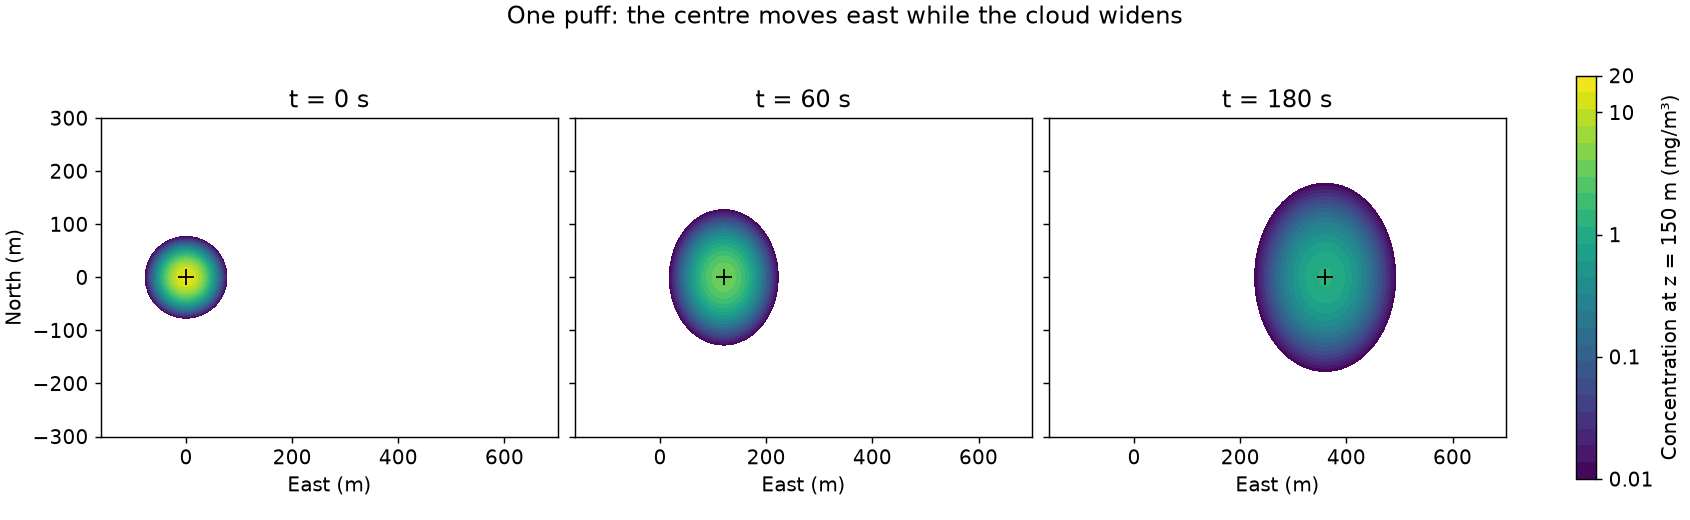

In [4]:
east_m = np.linspace(-160.0, 700.0, 201)
north_m = np.linspace(-300.0, 300.0, 141)
east_grid, north_grid = np.meshgrid(east_m, north_m, indexing="xy")
horizontal_points_m = np.stack((east_grid, north_grid), axis=-1)
plane_points_m = np.dstack((east_grid, north_grid, np.full_like(east_grid, source_m[2])))
single_concentrations = [
    puff_concentration(state, plane_points_m, boundary="free") for state in single_states
]
levels_mg_m3 = np.geomspace(0.01, 20.0, 25)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
for ax, state, concentration in zip(axes, single_states, single_concentrations, strict=True):
    image = ax.contourf(
        east_grid,
        north_grid,
        concentration * 1e6,
        levels=levels_mg_m3,
        norm=LogNorm(0.01, 20.0),
        cmap="viridis",
    )
    ax.plot(*state.centres_m[0, :2], "+", color="black", markersize=9)
    ax.set(title=f"t = {state.time_s:g} s", xlabel="East (m)", aspect="equal")
axes[0].set_ylabel("North (m)")
fig.colorbar(
    image,
    ax=axes,
    label="Concentration at z = 150 m (mg/m³)",
    ticks=[0.01, 0.1, 1.0, 10.0, 20.0],
    format="%g",
    shrink=0.85,
)
fig.suptitle("One puff: the centre moves east while the cloud widens")
show_figure(fig)

### Check against the uniform-forcing solution

For constant velocity **u** and diffusivity **K**, the expected centre is **c(t) = c(0) + ut** and covariance is **Σ(t) = Σ(0) + 2Kt**. The centre concentration is **M / ((2π)³ᐟ² √det Σ)**. These checks use the full three-dimensional free-space Gaussian.

In [5]:
for state in single_states:
    expected_centre = source_m + velocity_m_s * state.time_s
    expected_covariance = initial_covariance_m2 + 2.0 * diffusion_m2_s * state.time_s
    np.testing.assert_allclose(state.centres_m[0], expected_centre, rtol=1e-10, atol=1e-10)
    np.testing.assert_allclose(state.covariances_m2[0], expected_covariance, rtol=1e-10, atol=1e-10)
    expected_peak = 1.0 / ((2.0 * np.pi) ** 1.5 * np.sqrt(np.linalg.det(expected_covariance)))
    peak = puff_concentration(state, state.centres_m, boundary="free")[0]
    np.testing.assert_allclose(peak, expected_peak, rtol=1e-10, atol=0.0)
    np.testing.assert_allclose(state.masses_kg.sum(), 1.0, rtol=0.0, atol=1e-12)
    print(
        f"t = {state.time_s:5.0f} s: east = {state.centres_m[0, 0]:6.1f} m, "
        f"peak = {peak * 1e6:6.3f} mg/m³"
    )
print("Centre, covariance, peak concentration and 1 kg mass checks passed.")

t =     0 s: east =    0.0 m, peak = 15.873 mg/m³
t =    60 s: east =  120.0 m, peak =  3.913 mg/m³
t =   180 s: east =  360.0 m, peak =  1.205 mg/m³
Centre, covariance, peak concentration and 1 kg mass checks passed.


## 3. Continuous emissions become a plume

Release 0.02 kg/s for 180 s at the same position. `discretize_puff_emissions` replaces each 10 s interval with a 0.2 kg puff at its midpoint. `simulate_puffs` transports the released population and returns snapshots with mass diagnostics.

The interval mass is exact at partition edges. Midpoint releases approximate emission timing; a shorter interval is needed when resolving finer source-near structure. These settings illustrate the API and a finite-duration plume.

In [6]:
emission_rate_kg_s = 0.02
output_times_s = np.array([60.0, 120.0, 180.0])
releases = discretize_puff_emissions(
    np.array([0.0, 180.0]),
    np.array([emission_rate_kg_s]),
    source_m[None, :],
    initial_covariance_m2[None, :, :],
    partition_times_s=np.arange(10.0, 181.0, 10.0),
)
plume_outputs = list(
    simulate_puffs(
        releases,
        output_times_s,
        wind,
        diffusivity,
        **transport_controls,
        wind_tolerance_m_s=0.01,
        diffusivity_tolerance_m2_s=0.01,
        split_fraction=0.5,
        max_puffs=100,
        max_split_rounds=10,
    )
)
plume_concentrations = [
    puff_concentration(state, plane_points_m, boundary="free")
    for state, diagnostics in plume_outputs
]

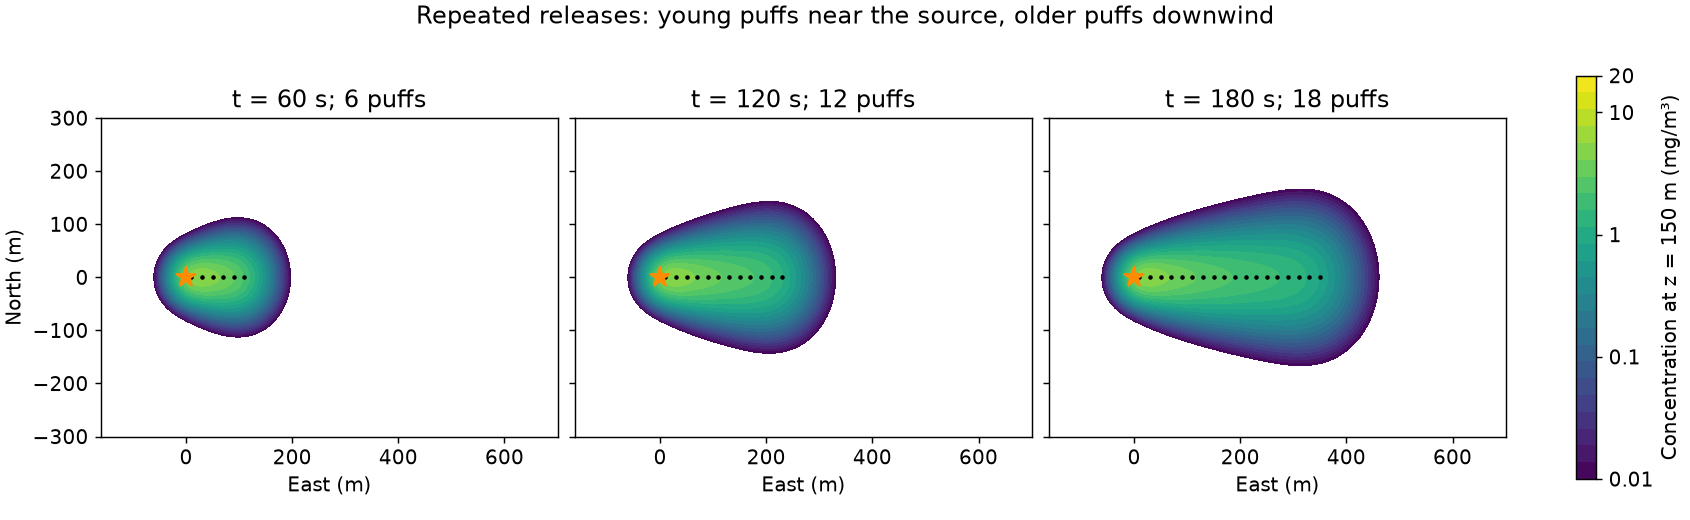

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True, layout="constrained")
for ax, (state, _diagnostics), concentration in zip(
    axes,
    plume_outputs,
    plume_concentrations,
    strict=True,
):
    image = ax.contourf(
        east_grid,
        north_grid,
        concentration * 1e6,
        levels=levels_mg_m3,
        norm=LogNorm(0.01, 20.0),
        cmap="viridis",
    )
    ax.plot(state.centres_m[:, 0], state.centres_m[:, 1], ".", color="black", markersize=3)
    ax.plot(0.0, 0.0, "*", color="darkorange", markersize=12)
    ax.set(
        title=f"t = {state.time_s:g} s; {len(state.masses_kg)} puffs",
        xlabel="East (m)",
        aspect="equal",
    )
axes[0].set_ylabel("North (m)")
fig.colorbar(
    image,
    ax=axes,
    label="Concentration at z = 150 m (mg/m³)",
    ticks=[0.01, 0.1, 1.0, 10.0, 20.0],
    format="%g",
    shrink=0.85,
)
fig.suptitle("Repeated releases: young puffs near the source, older puffs downwind")
show_figure(fig)

## 4. Compare concentration with mass per unit area

Concentration describes a point in space, in kg/m³. `puff_layer_columns` integrates through specified height layers and returns kg/m². Here a single layer spans 0 to 300 m; `[..., 0]` selects that layer.

The maps below show the same plume at 180 s. Their units and colour scales differ. The star marks the source; the dots above mark individual puff centres.

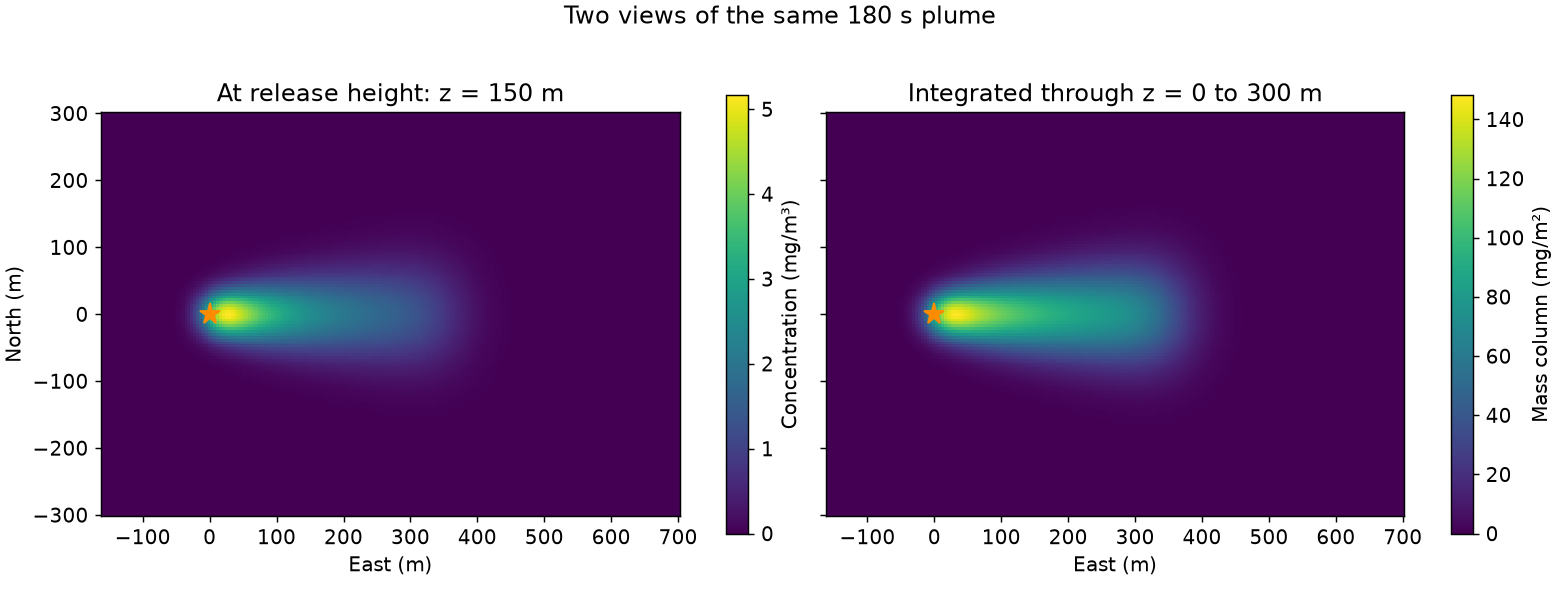

In [8]:
final_state, final_diagnostics = plume_outputs[-1]
height_edges_m = np.array([0.0, 300.0])
column_kg_m2 = puff_layer_columns(
    final_state,
    horizontal_points_m,
    height_edges_m,
    boundary="free",
)[..., 0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout="constrained")
for ax, values, title, units in zip(
    axes,
    [plume_concentrations[-1] * 1e6, column_kg_m2 * 1e6],
    ["At release height: z = 150 m", "Integrated through z = 0 to 300 m"],
    ["Concentration (mg/m³)", "Mass column (mg/m²)"],
    strict=True,
):
    image = ax.pcolormesh(east_grid, north_grid, values, shading="auto", cmap="viridis")
    ax.plot(0.0, 0.0, "*", color="darkorange", markersize=12)
    ax.set(title=title, xlabel="East (m)", aspect="equal")
    fig.colorbar(image, ax=ax, label=units, shrink=0.8)
axes[0].set_ylabel("North (m)")
fig.suptitle("Two views of the same 180 s plume")
show_figure(fig)

### Account for the emitted mass

The expected released mass is **rate × elapsed time** at these output times. Diagnostics account for the entire puff population, including tails outside our maps. Integrating the column map over horizontal area gives a separate numerical estimate on a finite box.

The map check allows a relative difference of 10⁻⁵ for finite support and trapezoidal quadrature in this example. Wider domains and finer grids are separate choices to assess for other inputs.

In [9]:
for state, diagnostics in plume_outputs:
    expected_mass_kg = emission_rate_kg_s * state.time_s
    np.testing.assert_allclose(diagnostics.released_mass_kg, expected_mass_kg, rtol=1e-12)
    np.testing.assert_allclose(diagnostics.active_mass_kg, expected_mass_kg, rtol=1e-12)
    assert abs(diagnostics.mass_residual_kg) < 1e-12
    print(f"t = {state.time_s:5.0f} s: released = active = {diagnostics.active_mass_kg:.3f} kg")

map_mass_kg = np.trapezoid(np.trapezoid(column_kg_m2, east_m, axis=1), north_m)
map_relative_error = abs(map_mass_kg / final_diagnostics.active_mass_kg - 1.0)
np.testing.assert_allclose(map_mass_kg, final_diagnostics.active_mass_kg, rtol=1e-5, atol=0.0)
assert final_diagnostics.below_ground_mass_kg < 1e-10
print(f"Column-map integral: {map_mass_kg:.8f} kg; relative difference: {map_relative_error:.2e}")
print(f"Free-space mass below z = 0: {final_diagnostics.below_ground_mass_kg:.2e} kg")
print(f"Elapsed tutorial time: {perf_counter() - started:.2f} s")
print(f"GIL enabled after calculations: {sys._is_gil_enabled()}")

t =    60 s: released = active = 1.200 kg
t =   120 s: released = active = 2.400 kg
t =   180 s: released = active = 3.600 kg
Column-map integral: 3.59999996 kg; relative difference: 1.14e-08
Free-space mass below z = 0: 2.17e-13 kg
Elapsed tutorial time: 0.47 s
GIL enabled after calculations: False


## Try a small change

- Change `velocity_m_s[0]` to move the plume faster or slower.
- Change the horizontal diffusivities to see the widths respond.
- Halve the release interval and compare the plume near the source.

Rerun all cells after a change. The examples assume uniform wind, constant diffusivity and a passive tracer. Chemistry, deposition, buoyancy and terrain are outside this demonstration. The saved checks establish the illustrated numerical behavior; physical realism needs application-specific evidence.

See the [Dispersion guide](../libs/orsia-dispersion/README.md) for the library scope and the [transport and evaluation reference](../libs/orsia-dispersion/docs/transport-and-evaluation.md) for reflecting-ground restrictions, finite-support integrals and numerical controls.